In [1]:
import sys
sys.path.append("../..")

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib
import os
from surgeNN import io
import gcsfs
fs = gcsfs.GCSFileSystem() #list stores, stripp zarr from filename, load 

In [2]:
from surgeNN import evaluation
p = np.arange(0.1,1.1,.05)
r = np.arange(0.1,1.1,.05)
[P,R] = np.meshgrid(p,r)
f1_contours = evaluation.compute_f1(P,R)

In [3]:
#Script plots the performance of LSTM models trained with the backward extension of ERA5 vs not.

In [4]:
#configure the script
tg        = 'esbjerg-esb-dnk-dmi.csv'#'brest-822a-fra-uhslc.csv'#
max_timesteps_between_extremes = 3

folders = [['/home/jovyan/surgeNN/results/nns/length_tests/default/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/length_tests/long/performance/lstm',
           ]]
models = ['lstm']

labels = ['def','long']

model_datasets={}
for m,model in enumerate(models):
    datasets=[]
    for folder in folders[m]:
        dir_name = folder

        ds =io.Output(dir_name)
        ds.open_performance_data([tg])
        ds.data = ds.data.sel(max_timesteps_between_extremes=max_timesteps_between_extremes).load()

        observed_thresholds = ds.observed_thresholds()
        ds = ds.data
        ds['observed_thresholds'] = observed_thresholds
        datasets.append(ds)

    '''
    ds = xr.concat(datasets,dim='test',coords='different')
    ds['test'] = folders[m]
    
    model_datasets[model] = ds
    '''
    
codec = xr.open_dataset('/home/jovyan/surgeNN/results/nns/length_tests/CoDEC_ERA5_at_gesla3_tgs_eu_performance.nc')


where_observed_peaks = (datasets[0].o.isel(it=0)>=observed_thresholds)
if max_timesteps_between_extremes>0:
    where_observed_peaks = ((where_observed_peaks) & (where_observed_peaks.rolling(time=1+2*int(max_timesteps_between_extremes),center='True').sum()>1)) #from 'compute_statistics_on_output_ds'\n",

In [8]:
datasets[0].split_kwargs

"{'method': 'by_years', 'split_years': [array([1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990,\n       1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001]), array([2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]), array([2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009])]}"

In [26]:
datasets[1].split_kwargs

"{'method': 'by_years', 'split_years': [array([1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960,\n       1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,\n       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,\n       1983, 1984, 1985, 1986, 1987, 1988, 1989]), array([2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]), array([1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,\n       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009])]}"

Text(0.5, 0, 'Relative RMSE [-]')

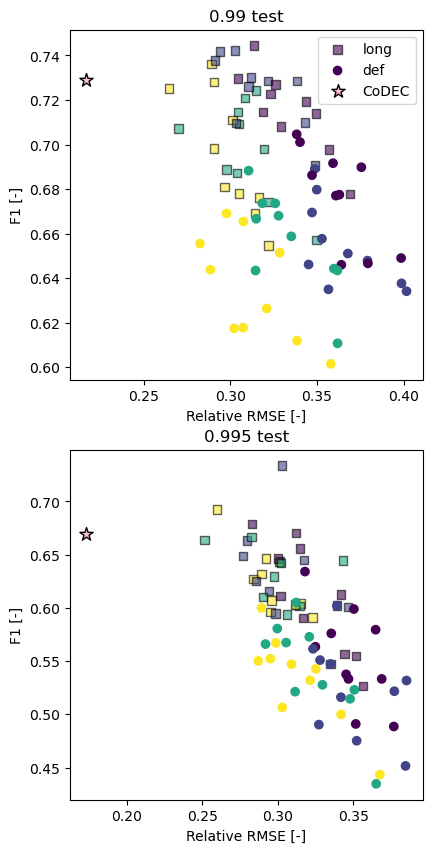

In [27]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='test'
ax = fig.add_subplot(221)

#ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
#            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(223)

#ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
#            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),marker='s',label=labels[1],zorder=0,edgecolor='black',alpha=.6)

ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.rmse_extremes.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv')/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
                                      codec.f1.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')


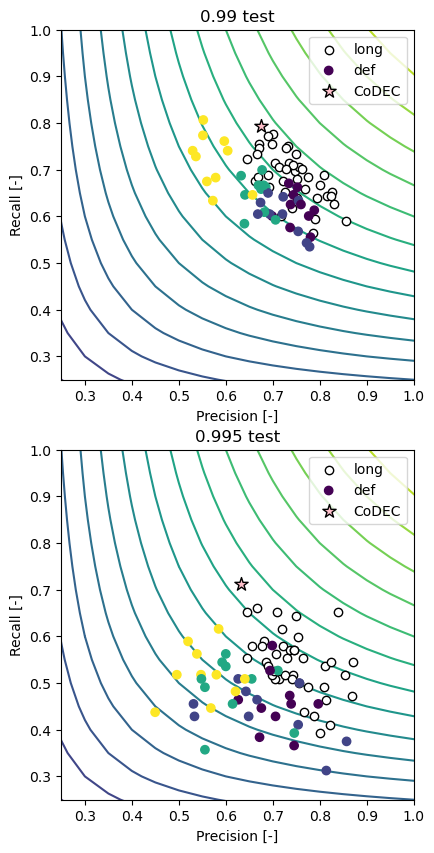

In [28]:
fig = plt.figure(figsize=(10,10))


quantile=.99
split='test'
ax = fig.add_subplot(221)

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(223)

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()
